# Challenge 3: evaluación final e inferencia

El modelo ya fue seleccionado. Ahora debes abrir el conjunto de test una sola vez, comunicar su desempeño y comprobar que el pipeline puede reutilizarse con datos nuevos.

**Entradas:** `test.csv`, `data_contract.json` y `champion_model.joblib`  
**Salidas:** `test_metrics.json`, `batch_predictions.csv`

In [2]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/semana6')
print(os.listdir('.'))

Mounted at /content/drive
['data', 'artifacts', 'reports']


In [3]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
)

In [4]:
from pathlib import Path

PROJECT_DIR = Path.cwd()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

RAW_DATA_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
REPORTS_DIR = PROJECT_DIR / "reports"

for directory in (PROCESSED_DATA_DIR, ARTIFACTS_DIR, REPORTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42

## 1. Carga del modelo y del conjunto de prueba

In [5]:
contract = json.loads((ARTIFACTS_DIR / "data_contract.json").read_text(encoding="utf-8"))
training_metadata = json.loads((ARTIFACTS_DIR / "training_metadata.json").read_text(encoding="utf-8"))
model = joblib.load(ARTIFACTS_DIR / "champion_model.joblib")

test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")
X_test = test_df[contract["features"]]
y_test = test_df[contract["target"]]

print("Modelo:", training_metadata["champion"])
print("Test:", X_test.shape)

Modelo: logistic_regression
Test: (36, 13)


## 2. Evaluación final

Accuracy test: 0.9722
F1 macro test: 0.9710

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36



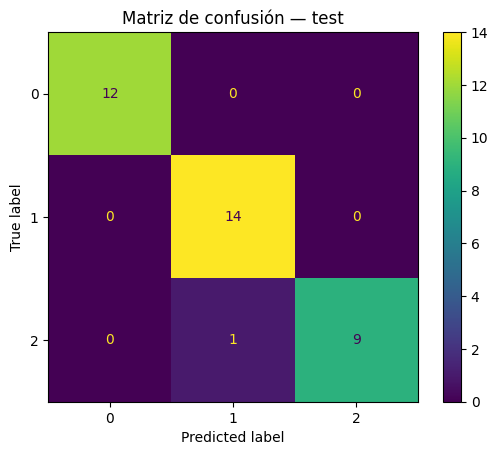

In [7]:
y_pred = model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred, average="macro")
print(f"Accuracy test: {test_accuracy:.4f}")
print(f"F1 macro test: {test_f1:.4f}\n")

print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Matriz de confusión — test")
plt.show()

**Análisis:**

> ¿El desempeño es coherente con validación cruzada? ¿Qué clases se confunden? ¿Hay evidencia de sobreajuste?

Sí, es coherente: accuracy en test 97.2 % frente a 97.9 % en validación
cruzada. Solo hubo un error en 36 vinos: uno de clase 2 clasificado como clase 1.
No hay evidencia de sobreajuste, porque el resultado en test es casi igual al de CV.

## 3. Función de inferencia

In [8]:
feature_columns = contract["features"]

def predict(records: pd.DataFrame) -> pd.DataFrame:
    """Valida el esquema y devuelve las predicciones del pipeline."""
    # Verificar que no falten columnas
    missing = set(feature_columns) - set(records.columns)
    if missing:
        raise ValueError(f"Faltan columnas: {sorted(missing)}")

    # Ordenar las columnas igual que en el entrenamiento
    X = records[feature_columns]

    # Predicción + probabilidad de cada clase
    result = pd.DataFrame(index=records.index)
    result["prediction"] = model.predict(X)
    probas = model.predict_proba(X)
    for i, cls in enumerate(model.classes_):
        result[f"proba_{cls}"] = probas[:, i].round(4)
    return result

## 4. Predicción por lotes

In [9]:
new_records = X_test.iloc[:5].copy()

batch_predictions = predict(new_records)
batch_predictions.to_csv(REPORTS_DIR / "batch_predictions.csv", index=False)
print(batch_predictions)

   prediction  proba_0  proba_1  proba_2
0           0   0.9997   0.0003   0.0000
1           1   0.0071   0.5404   0.4525
2           0   0.9920   0.0077   0.0003
3           1   0.2900   0.7075   0.0026
4           1   0.0330   0.9623   0.0047


## 5. Reporte final

In [10]:
test_metrics = {
    "model": training_metadata["champion"],
    "cv_accuracy": training_metadata["cv_accuracy"],
    "test_accuracy": float(test_accuracy),
    "test_f1_macro": float(test_f1),
}
with open(REPORTS_DIR / "test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)
print(test_metrics)

{'model': 'logistic_regression', 'cv_accuracy': 0.9790640394088669, 'test_accuracy': 0.9722222222222222, 'test_f1_macro': 0.9709618874773139}


In [11]:
assert (REPORTS_DIR / "test_metrics.json").exists()
assert (REPORTS_DIR / "batch_predictions.csv").exists()
print("Challenge 3 completado.")

Challenge 3 completado.


## Resumen ejecutivo

| Elemento | Resultado |
|---|---|
| Modelo campeón | Regresión logística (C = 1) |
| Accuracy CV | 97.9 % |
| Accuracy test | 97.2 % |
| F1 macro test | 97.1 % |
| Clases más confundidas | 2 → 1 (un solo caso) |
| Principal limitación | El dataset es muy pequeño (178 vinos, 36 en test): un solo error cambia el accuracy casi 3 % |

## Checklist

- [ ] Evalué únicamente el modelo campeón.
- [ ] No reajusté hiperparámetros después de observar test.
- [ ] Implementé validación básica del esquema de entrada.
- [ ] Generé predicciones por lotes.
- [ ] Guardé las métricas finales.